In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Environment ready!")

Environment ready!


In [5]:
from google.colab import files

uploaded = files.upload()

Saving default+of+credit+card+clients.zip to default+of+credit+card+clients.zip


In [8]:
import zipfile
import os
import pandas as pd

# Get the uploaded ZIP filename
zip_path = next(iter(uploaded.keys()))

# Extract the contents
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/credit_data")

# Find the extracted Excel file
for root, dirs, filenames in os.walk("/content/credit_data"):
    for filename in filenames:
        print(os.path.join(root, filename))

/content/credit_data/default of credit card clients.xls


In [9]:
file_path = "/content/credit_data/default of credit card clients.xls"

df = pd.read_excel(file_path, header=1)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [10]:
# Check for missing values
print("Missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

Missing values: 0
Duplicate rows: 0

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


In [13]:
target_col = "default payment next month"

print("Number of clients in each class:")
print(df[target_col].value_counts().sort_index())

print("\nProportion of each class:")
print(df[target_col].value_counts(normalize=True).sort_index().round(3))

Number of clients in each class:
default payment next month
0    23364
1     6636
Name: count, dtype: int64

Proportion of each class:
default payment next month
0    0.779
1    0.221
Name: proportion, dtype: float64


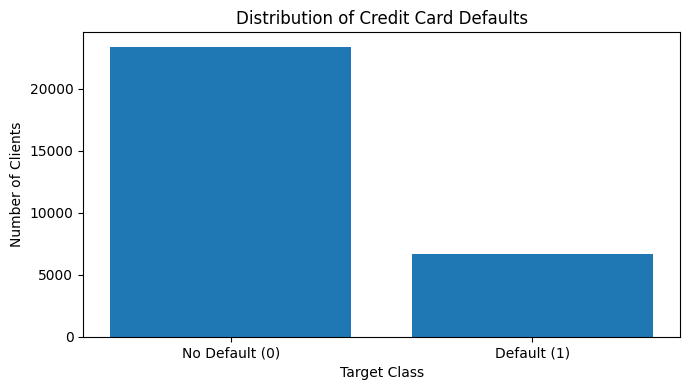

In [14]:
import matplotlib.pyplot as plt

counts = df[target_col].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(
    ["No Default (0)", "Default (1)"],
    counts.values
)

plt.title("Distribution of Credit Card Defaults")
plt.xlabel("Target Class")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()

In [15]:
default_by_pay = df.groupby("PAY_0")[
    "default payment next month"
].agg(["count", "mean"])

default_by_pay.columns = [
    "Number of Clients",
    "Default Rate"
]

default_by_pay["Default Rate"] *= 100

display(default_by_pay.round(2))

,Number of Clients,Default Rate
PAY_0,,
-2,2759,13.23
-1,5686,16.78
0,14737,12.81
1,3688,33.95
2,2667,69.14
3,322,75.78
4,76,68.42
5,26,50.00
6,11,54.55


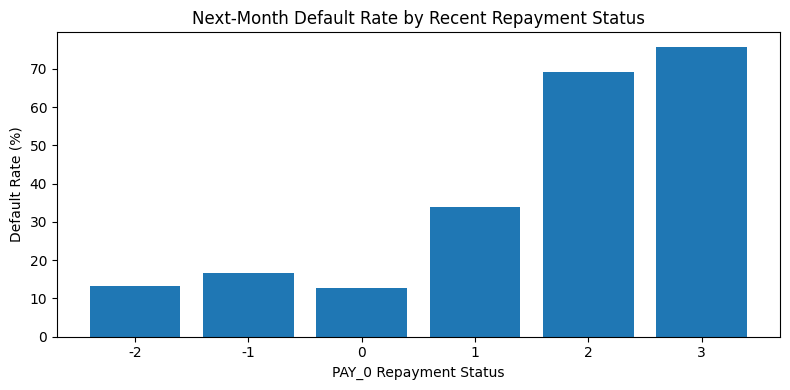

In [16]:
import matplotlib.pyplot as plt

# Exclude categories with very few observations for a clearer trend chart
pay_counts = df["PAY_0"].value_counts()
common_statuses = pay_counts[pay_counts >= 100].index

plot_data = default_by_pay.loc[common_statuses].sort_index()

plt.figure(figsize=(8, 4))
plt.bar(
    plot_data.index.astype(str),
    plot_data["Default Rate"]
)

plt.title("Next-Month Default Rate by Recent Repayment Status")
plt.xlabel("PAY_0 Repayment Status")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

In [17]:
# Group clients by credit limit
df["credit_limit_group"] = pd.cut(
    df["LIMIT_BAL"],
    bins=[0, 50000, 100000, 200000, 500000, float("inf")],
    labels=["0-50K", "50K-100K", "100K-200K",
            "200K-500K", "500K+"],
    include_lowest=True
)

# Calculate client counts and default rates
credit_analysis = df.groupby(
    "credit_limit_group",
    observed=False
)["default payment next month"].agg(
    ["count", "mean"]
)

credit_analysis.columns = [
    "Number of Clients",
    "Default Rate"
]

credit_analysis["Default Rate"] *= 100

display(credit_analysis.round(2))

,Number of Clients,Default Rate
credit_limit_group,,
0-50K,7676,31.79
50K-100K,4822,25.80
100K-200K,7880,19.48
200K-500K,9416,14.80
500K+,206,11.17


In [18]:
from sklearn.model_selection import train_test_split

# Separate target and predictors
target_col = "default payment next month"

X = df.drop(
    columns=[target_col, "ID", "credit_limit_group"]
).copy()

y = df[target_col].copy()

# Create training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (24000, 23)
Testing features: (6000, 23)

Training target proportions:
default payment next month
0    0.779
1    0.221
Name: proportion, dtype: float64

Testing target proportions:
default payment next month
0    0.779
1    0.221
Name: proportion, dtype: float64


Accuracy: 0.8088
Precision: 0.6923
Recall: 0.2442
F1-score: 0.361
ROC-AUC: 0.71

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4673
           1       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.76      0.61      0.62      6000
weighted avg       0.79      0.81      0.77      6000



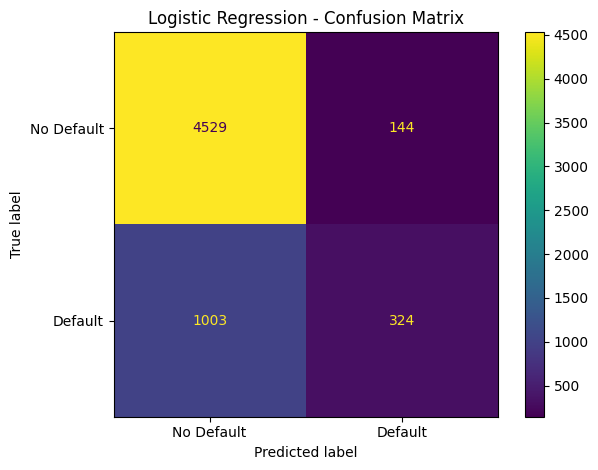

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Recreate the target and features
target_col = "default payment next month"

X = df.drop(
    columns=[target_col, "ID", "credit_limit_group"],
    errors="ignore"
)
y = df[target_col]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=42, stratify=y
)

# Identify categorical and numerical features
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE"]
numeric_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

# Preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Define and train the model
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

# Generate predictions
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No Default", "Default"]
)
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Split the original training data into training and validation
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a balanced logistic regression model
balanced_model = clone(logistic_model)
balanced_model.set_params(
    classifier__class_weight="balanced"
)

# Train only on the subtraining data
balanced_model.fit(X_subtrain, y_subtrain)

# Evaluate on validation data
val_pred = balanced_model.predict(X_val)
val_prob = balanced_model.predict_proba(X_val)[:, 1]

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Balanced Logistic Regression": [
        accuracy_score(y_val, val_pred),
        precision_score(y_val, val_pred),
        recall_score(y_val, val_pred),
        f1_score(y_val, val_pred),
        roc_auc_score(y_val, val_prob)
    ]
})

display(results.round(4))

,Metric,Balanced Logistic Regression
0,Accuracy,0.6915
1,Precision,0.3837
2,Recall,0.6507
3,F1-score,0.4827
4,ROC-AUC,0.7257


In [22]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
import pandas as pd

# Train the baseline on the same subtraining set
baseline_model = clone(logistic_model)
baseline_model.fit(X_subtrain, y_subtrain)

# Train the balanced model on the same subtraining set
balanced_model = clone(logistic_model)
balanced_model.set_params(
    classifier__class_weight="balanced"
)
balanced_model.fit(X_subtrain, y_subtrain)

models = {
    "Baseline": baseline_model,
    "Balanced": balanced_model
}

rows = []

for name, model in models.items():
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1-score": f1_score(y_val, pred),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Baseline,0.8125,0.7066,0.2608,0.3810,0.7244
Balanced,0.6915,0.3837,0.6507,0.4827,0.7257


In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Reuse the preprocessing pipeline
tree_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=42
    ))
])

# Train on the same subtraining data
tree_model.fit(X_subtrain, y_subtrain)

# Evaluate on the same validation data
tree_pred = tree_model.predict(X_val)
tree_prob = tree_model.predict_proba(X_val)[:, 1]

tree_results = pd.DataFrame([{
    "Model": "Balanced Decision Tree",
    "Accuracy": accuracy_score(y_val, tree_pred),
    "Precision": precision_score(y_val, tree_pred),
    "Recall": recall_score(y_val, tree_pred),
    "F1-score": f1_score(y_val, tree_pred),
    "ROC-AUC": roc_auc_score(y_val, tree_prob)
}]).set_index("Model")

display(tree_results.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Balanced Decision Tree,0.7748,0.4922,0.5669,0.5269,0.7605


Best validation threshold: 0.5094
Validation precision: 0.4922
Validation recall: 0.5669
Validation F1-score: 0.5269


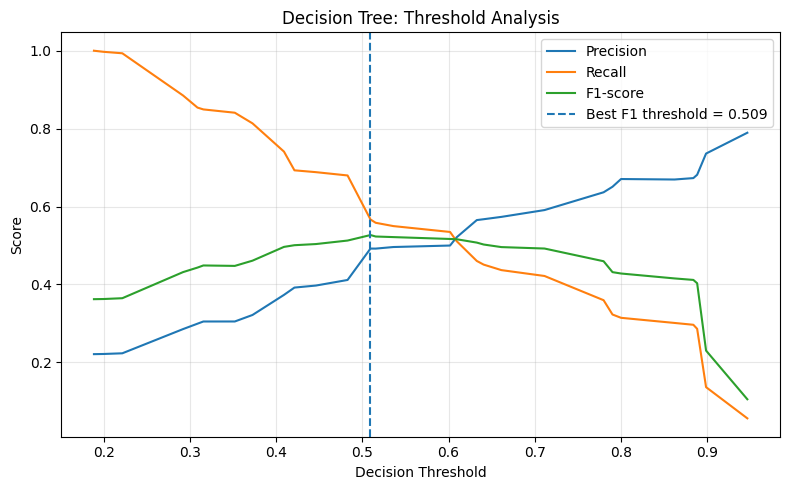

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    auc
)

# Get default probabilities on the validation set
tree_val_prob = tree_model.predict_proba(X_val)[:, 1]

# Calculate precision and recall across thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, tree_val_prob
)

# Calculate F1-score for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Select the threshold with the highest validation F1
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Best validation threshold:", round(best_threshold, 4))
print("Validation precision:", round(precision[best_idx], 4))
print("Validation recall:", round(recall[best_idx], 4))
print("Validation F1-score:", round(f1_scores[best_idx], 4))

# Plot precision and recall against threshold
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1-score")

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best F1 threshold = {best_threshold:.3f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Decision Tree: Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Final Test Results
------------------
Accuracy: 0.771
Precision: 0.4845
Recall: 0.5546
F1-score: 0.5172
ROC-AUC: 0.7592

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      4673
           1       0.48      0.55      0.52      1327

    accuracy                           0.77      6000
   macro avg       0.68      0.69      0.68      6000
weighted avg       0.78      0.77      0.78      6000



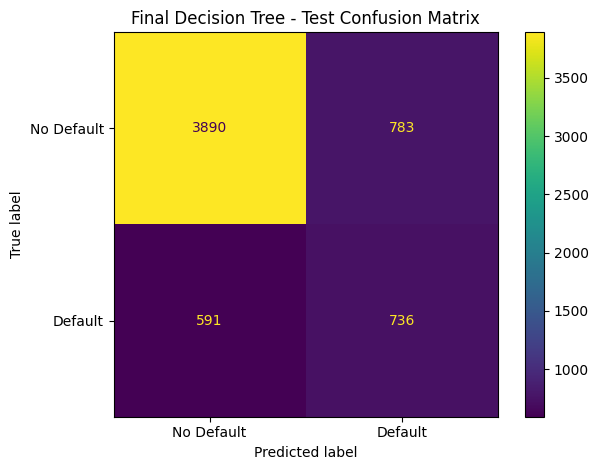

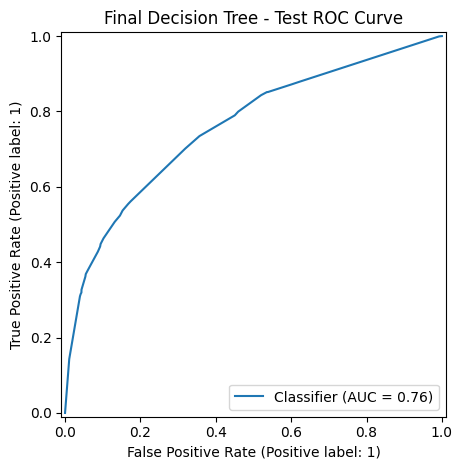

In [25]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
import matplotlib.pyplot as plt

# Select the threshold using validation results
best_threshold = 0.5094

# Retrain on the complete training set
final_model = clone(tree_model)
final_model.fit(X_train, y_train)

# Evaluate on the untouched test set
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("Final Test Results")
print("------------------")
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred), 4))
print("Recall:", round(recall_score(y_test, test_pred), 4))
print("F1-score:", round(f1_score(y_test, test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No Default", "Default"]
)
plt.title("Final Decision Tree - Test Confusion Matrix")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title("Final Decision Tree - Test ROC Curve")
plt.tight_layout()
plt.show()

,Feature,Importance
2,num__PAY_0,0.7497
15,num__PAY_AMT2,0.0741
5,num__PAY_4,0.0383
0,num__LIMIT_BAL,0.0265
4,num__PAY_3,0.0218
3,num__PAY_2,0.0211
16,num__PAY_AMT3,0.0149
17,num__PAY_AMT4,0.0140
14,num__PAY_AMT1,0.0106
9,num__BILL_AMT2,0.0090


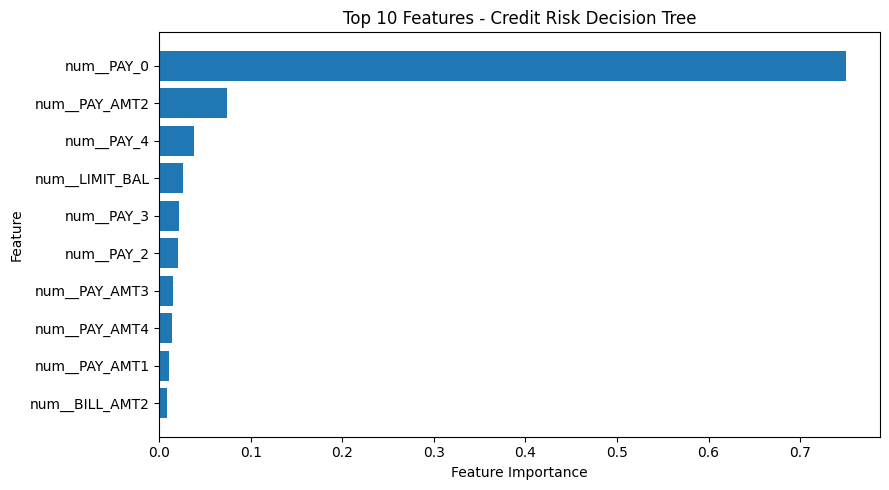

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract the trained decision tree
trained_tree = final_model.named_steps["classifier"]

# Retrieve feature names after preprocessing
feature_names = (
    final_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Calculate feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_tree.feature_importances_
}).sort_values("Importance", ascending=False)

# Display the top 10 features
display(importance_df.head(10).round(4))

# Plot the top 10 features
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 5))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Features - Credit Risk Decision Tree")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [27]:
import joblib
import json

# Save the final trained model
joblib.dump(final_model, "/content/credit_risk_model.pkl")

# Save the selected decision threshold
with open("/content/model_config.json", "w") as f:
    json.dump({
        "model": "Balanced Decision Tree",
        "threshold": 0.5094,
        "target": "default payment next month",
        "test_accuracy": 0.7710,
        "test_precision": 0.4845,
        "test_recall": 0.5546,
        "test_f1": 0.5172,
        "test_roc_auc": 0.7592
    }, f, indent=4)

print("Model and configuration saved!")

Model and configuration saved!


In [28]:
from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

project_dir = "/content/drive/MyDrive/Credit_Risk_Prediction"
os.makedirs(project_dir, exist_ok=True)

# Copy model and configuration to Drive
shutil.copy(
    "/content/credit_risk_model.pkl",
    project_dir
)

shutil.copy(
    "/content/model_config.json",
    project_dir
)

print("Project backup folder:", project_dir)

Mounted at /content/drive
Project backup folder: /content/drive/MyDrive/Credit_Risk_Prediction
